# Comparison of kernel ridge and Gaussian process regression (KRR parts): scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/gaussian_process/plot_compare_gpr_krr.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/gaussian_process/plot_compare_gpr_krr.html)).

**Scenario:** 40 noisy samples of `sin` on `[0, 12]` (`RandomState(0)`), predicted on 1000 points of `[0, 30]`:
`Ridge()` as the linear baseline, `KernelRidge(kernel=ExpSineSquared())` with default hyperparameters, and the
`RandomizedSearchCV(kernel_ridge, {"alpha": loguniform(1, 1e3), "kernel__length_scale": loguniform(1e-2, 1e2),
"kernel__periodicity": loguniform(1, 10)}, n_iter=500, random_state=0)` tuning, then the tuned model's predictions.
This notebook covers the KernelRidge (and Ridge) parts; the `GaussianProcessRegressor` half belongs to the
gaussian_process family and is not replayed.

**Adaptations:**
- sklearn passes a Gaussian-process kernel object as `kernel`. Moxie's KernelRidge takes typed native callables
  (`RowKernel`, documented family adaptation), so the notebook defines `ExpSineSquared` as a 15-line `RowKernel`
  struct computing sklearn's formula `exp(-2 sin(pi d / p)^2 / l^2)`. Moxie's `gaussian_process.kernels.ExpSineSquared`
  does not plug into KernelRidge (recorded as a GAP).
- Nested `kernel__length_scale`/`kernel__periodicity` names are not routed by string in Moxie (documented
  `interfaces.md` difference). A typed `CVAdapter` rebuilds the kernel struct per candidate instead.
- The 500 candidates are the ones sklearn's `RandomizedSearchCV` drew (shared from `cv_results_["params"]`);
  Moxie evaluates each with `cross_val_score` over the same five unshuffled folds and picks the best. Reproducing
  scipy's `loguniform` sampling stream is model_selection's concern, not this family's.
- Figures are smaller (dpi 60).

**Determinism:** deterministic. Seeded data, seeded candidate sampling (done once, in Python), closed-form solves and
unshuffled folds.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("kernel_ridge/plot_compare_gpr_krr")

## 1. scikit-learn (Python reference)

Fitting KernelRidge with default kernel: 0.001 seconds
ExpSineSquared(length_scale=1, periodicity=1)


Time for KernelRidge fitting: 2.430 seconds
{'alpha': np.float64(1.991584977345022), 'kernel__length_scale': np.float64(0.7986499491396734), 'kernel__periodicity': np.float64(6.6072758064261095)}


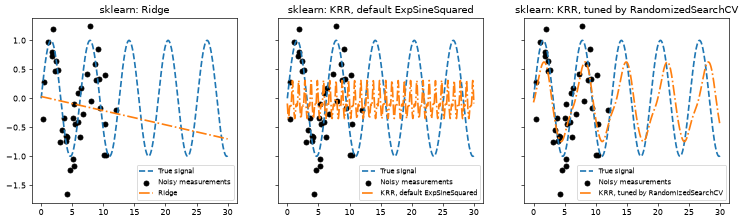

In [2]:
import time
import matplotlib.pyplot as plt
import numpy as np

rng = np.random.RandomState(0)
data = np.linspace(0, 30, num=1_000).reshape(-1, 1)
target = np.sin(data).ravel()
training_sample_indices = rng.choice(np.arange(0, 400), size=40, replace=False)
training_data = data[training_sample_indices]
training_noisy_target = target[training_sample_indices] + 0.5 * rng.randn(len(training_sample_indices))

from sklearn.linear_model import Ridge
ridge = Ridge().fit(training_data, training_noisy_target)

from sklearn.gaussian_process.kernels import ExpSineSquared
from sklearn.kernel_ridge import KernelRidge
kernel_ridge = KernelRidge(kernel=ExpSineSquared())
start_time = time.time()
kernel_ridge.fit(training_data, training_noisy_target)
print(f"Fitting KernelRidge with default kernel: {time.time() - start_time:.3f} seconds")
print(kernel_ridge.kernel)

from scipy.stats import loguniform
from sklearn.model_selection import RandomizedSearchCV
param_distributions = {
    "alpha": loguniform(1e0, 1e3),
    "kernel__length_scale": loguniform(1e-2, 1e2),
    "kernel__periodicity": loguniform(1e0, 1e1),
}
kernel_ridge_tuned = RandomizedSearchCV(kernel_ridge, param_distributions=param_distributions, n_iter=500, random_state=0)
start_time = time.time()
kernel_ridge_tuned.fit(training_data, training_noisy_target)
print(f"Time for KernelRidge fitting: {time.time() - start_time:.3f} seconds")
print(kernel_ridge_tuned.best_params_)
predictions_kr = kernel_ridge_tuned.predict(data)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), dpi=60, sharey=True)
for ax, pred, title in zip(axes, (ridge.predict(data), kernel_ridge.predict(data), predictions_kr),
                           ("Ridge", "KRR, default ExpSineSquared", "KRR, tuned by RandomizedSearchCV")):
    ax.plot(data, target, label="True signal", linewidth=2, linestyle="dashed")
    ax.scatter(training_data, training_noisy_target, color="black", label="Noisy measurements")
    ax.plot(data, pred, label=title, linewidth=2, linestyle="dashdot")
    ax.set_title("sklearn: " + title); ax.legend(loc="lower right", fontsize=8)
plt.show()
cand = kernel_ridge_tuned.cv_results_["params"]
candidates = np.array([[p["alpha"], p["kernel__length_scale"], p["kernel__periodicity"]] for p in cand])
nb.share(X=training_data, y=training_noisy_target, data=data, candidates=candidates)

## 2. Moxie (native Mojo)

In [3]:
%%mojo krr
import numojo as nm
from numojo import NDArray, Shape, Item
from std.math import exp, sin, sqrt, pi
from moxie.kernel_ridge import KernelRidge, RowKernel
from moxie.linear_model import Ridge
from moxie.model_selection import IndexArray, IndexSplit, KFold, cross_val_score
from moxie.model_selection._evaluation import TypedScorer
from moxie.model_selection._validation import CVAdapter
from moxie.model_selection._split import _rows
from moxie_nb_io import load, save, save_floats, save_ints

comptime Dense = NDArray[DType.float64]


@fieldwise_init
struct ExpSineSquared(Copyable, RowKernel):
    """Sklearn's ExpSineSquared: exp(-2 sin(pi d / periodicity)^2 / length_scale^2), d Euclidean."""
    var length_scale: Float64
    var periodicity: Float64

    def evaluate[dtype: DType](self, X: nm.NDArray[dtype], i: Int, Y: nm.NDArray[dtype], j: Int) raises -> SIMD[dtype, 1]:
        var squared = Float64(0)
        for k in range(X.shape[1]):
            var diff = Float64(X.item(i, k)) - Float64(Y.item(j, k))
            squared += diff * diff
        var s = sin(pi * sqrt(squared) / self.periodicity) / self.length_scale
        return SIMD[dtype, 1](exp(-2 * s * s))


comptime KRR = KernelRidge[DType.float64, ExpSineSquared]


struct R2(TypedScorer):
    comptime Estimator = KRR
    comptime Input = Dense
    comptime Target = Dense
    comptime Metadata = NoneType

    def __init__(out self):
        pass

    def score(self, estimator: KRR, X: Dense, y: Dense, metadata: NoneType) raises -> Float64:
        return estimator.score(X, y)


struct Rows(CVAdapter):
    comptime Scorer = R2

    def __init__(out self):
        pass

    def n_samples(self, X: Dense, y: Dense) raises -> Int:
        return y.shape[0]

    def input_rows(self, X: Dense, rows: IndexArray, train: IndexArray) raises -> Dense:
        return _rows(X, rows)

    def target_rows(self, y: Dense, rows: IndexArray) raises -> Dense:
        return _rows(y, rows)

    def metadata_rows(self, metadata: NoneType, rows: IndexArray) raises -> NoneType:
        return None

    def fit(self, mut estimator: KRR, X: Dense, y: Dense, metadata: NoneType) raises:
        _ = estimator.fit(X, y)


def main() raises:
    var X = load("X")
    var y = load("y")
    var data = load("data")
    var candidates = load("candidates")

    var ridge = Ridge()
    _ = ridge.fit(X, y)
    save("ridge_pred", ridge.predict(data))

    var default = KRR(kernel=ExpSineSquared(1.0, 1.0))
    _ = default.fit(X, y)
    save("default_dual", default.dual_coef_[Dense])
    save("default_pred", default.predict(data)[Dense].copy())

    var cursor = KFold(5).split(y.shape[0])
    var splits = List[IndexSplit]()
    while True:
        var pair = cursor.next()
        if not pair:
            break
        splits.append(pair.value().copy())
    var means = Dense(Shape(candidates.shape[0]))
    var best = 0
    for c in range(candidates.shape[0]):
        var model = KRR(alpha=candidates.item(c, 0),
                        kernel=ExpSineSquared(candidates.item(c, 1), candidates.item(c, 2)))
        var scores = cross_val_score[Rows](model, X, y, Rows(), R2(), splits, None, None)
        var total = Float64(0)
        for k in range(scores.size):
            total += scores.item(k)
        means[Item(c)] = total / Float64(scores.size)
        if means.item(c) > means.item(best):
            best = c
    save("mean_test_score", means)
    save_ints("best_index", [best])
    var tuned = KRR(alpha=candidates.item(best, 0), kernel=ExpSineSquared(candidates.item(best, 1), candidates.item(best, 2)))
    _ = tuned.fit(X, y)
    save("tuned_pred", tuned.predict(data)[Dense].copy())
    print("best candidate", best, "alpha", candidates.item(best, 0), "length_scale", candidates.item(best, 1),
          "periodicity", candidates.item(best, 2), "mean R2", means.item(best))

best candidate 311 alpha 1.991584977345022 length_scale 0.7986499491396734 periodicity 6.6072758064261095 mean R2 0.38262933027762747


## 3. Side by side and parity

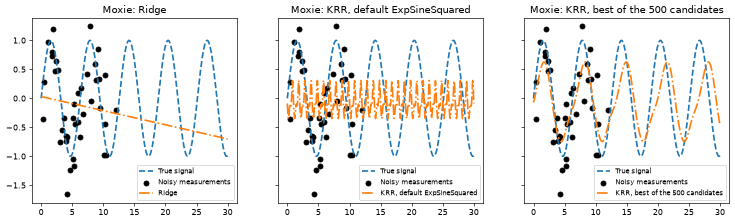

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
Ridge().predict(data),PASS,"(1000,)","(1000,)",3.33e-16,1.7e-13,"rtol=1e-12, atol=1e-12",,closed-form Float64 one-feature ridge; summation order only
KRR(ExpSineSquared()) dual_coef_,PASS,"(40,)","(40,)",4.94e-13,3.32e-12,"rtol=3e-09, atol=3e-09",,alpha >= 1 keeps K + alpha I well conditioned (cond <= 41 for 32 training rows); differences come from Cholesky/kernel summation order and libm sin/exp (family Float64 bound 3e-9)
KRR(ExpSineSquared()) predict(data),PASS,"(1000,)","(1000,)",4.96e-13,1.7e-10,"rtol=3e-09, atol=3e-09",,alpha >= 1 keeps K + alpha I well conditioned (cond <= 41 for 32 training rows); differences come from Cholesky/kernel summation order and libm sin/exp (family Float64 bound 3e-9)
500 candidates: mean_test_score,PASS,"(500,)","(500,)",1.74e-13,2.6e-11,"rtol=1e-09, atol=1e-09",,R2 of fold predictions within the solve bound above
best candidate index (best_params_),PASS,"(1,)","(1,)",,,exact,0 mismatches,
tuned KRR predict(data),PASS,"(1000,)","(1000,)",1.22e-13,4.75e-11,"rtol=3e-09, atol=3e-09",,alpha >= 1 keeps K + alpha I well conditioned (cond <= 41 for 32 training rows); differences come from Cholesky/kernel summation order and libm sin/exp (family Float64 bound 3e-9)
GP kernel object as KernelRidge kernel,GAP,,,,,,moxie.gaussian_process.kernels.ExpSineSquared is not a RowKernel; users write a native RowKernel struct (documented callable adaptation). Bridging the GP kernel family is cross-family work.,
RandomizedSearchCV with nested kernel__ parameters,ADAPTED,,,,,,"string routing of nested parameters is a documented interfaces.md difference; the candidates are evaluated through a typed CVAdapter instead, using sklearn's sampled values",
GaussianProcessRegressor half of the example,SKIP,,,,,,belongs to the gaussian_process family,


In [4]:
mx = nb.results["krr"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4), dpi=60, sharey=True)
for ax, pred, title in zip(axes, (mx["ridge_pred"], mx["default_pred"], mx["tuned_pred"]),
                           ("Ridge", "KRR, default ExpSineSquared", "KRR, best of the 500 candidates")):
    ax.plot(data, target, label="True signal", linewidth=2, linestyle="dashed")
    ax.scatter(training_data, training_noisy_target, color="black", label="Noisy measurements")
    ax.plot(data, pred, label=title, linewidth=2, linestyle="dashdot")
    ax.set_title("Moxie: " + title); ax.legend(loc="lower right", fontsize=8)
plt.show()
best = int(np.argmin(kernel_ridge_tuned.cv_results_["rank_test_score"]))
moxie_nb.side_by_side(sklearn_best=[best, kernel_ridge_tuned.best_score_], moxie_best=[mx["best_index"][0], mx["mean_test_score"][mx["best_index"][0]]])
SOLVE = ("alpha >= 1 keeps K + alpha I well conditioned (cond <= 41 for 32 training rows); differences come from "
         "Cholesky/kernel summation order and libm sin/exp (family Float64 bound 3e-9)")
nb.compare("Ridge().predict(data)", ridge.predict(data), mx["ridge_pred"], rtol=1e-12, atol=1e-12,
           reason="closed-form Float64 one-feature ridge; summation order only")
nb.compare("KRR(ExpSineSquared()) dual_coef_", kernel_ridge.dual_coef_, mx["default_dual"], rtol=3e-9, atol=3e-9, reason=SOLVE)
nb.compare("KRR(ExpSineSquared()) predict(data)", kernel_ridge.predict(data), mx["default_pred"], rtol=3e-9, atol=3e-9, reason=SOLVE)
nb.compare("500 candidates: mean_test_score", kernel_ridge_tuned.cv_results_["mean_test_score"], mx["mean_test_score"],
           rtol=1e-9, atol=1e-9, reason="R2 of fold predictions within the solve bound above")
nb.compare("best candidate index (best_params_)", [best], mx["best_index"], exact=True)
nb.compare("tuned KRR predict(data)", predictions_kr, mx["tuned_pred"], rtol=3e-9, atol=3e-9, reason=SOLVE)
nb.note("GP kernel object as KernelRidge kernel", "GAP",
        "moxie.gaussian_process.kernels.ExpSineSquared is not a RowKernel; users write a native RowKernel struct "
        "(documented callable adaptation). Bridging the GP kernel family is cross-family work.")
nb.note("RandomizedSearchCV with nested kernel__ parameters", "ADAPTED",
        "string routing of nested parameters is a documented interfaces.md difference; the candidates are evaluated "
        "through a typed CVAdapter instead, using sklearn's sampled values")
nb.note("GaussianProcessRegressor half of the example", "SKIP", "belongs to the gaussian_process family")
nb.report()
nb.assert_parity()